In [5]:
import torch
import torchvision
from torchvision.datasets import MNIST

In [6]:
from torchvision import transforms as T

In [7]:
tfs = T.Compose([T.Resize((28, 28)), T.Grayscale(num_output_channels=3), T.ToTensor()] ) # Resize rasmni 28 x 28 ga o'zgartiradi, Grayscale ->Kulrang rasmни 3 ta bir xil grayscale kanal bilan ifodalaydi., ToTensor -> tensor formatiga o'tkazadi

ds = MNIST(root="datasets", train=True, download=True, transform = tfs)
ts_ds = MNIST(root="datasets", train=False, download=True, transform = tfs)

In [8]:
classes = ds.classes
n_cls = len(classes)
n_train = len(ds)
n_cls
# bu yerda biz MNIST datasetidagi sinflar sonini va train datasetdagi rasm sonini hisoblayapmiz.

10

In [9]:
# Datamizni ajratib olish uchun quyidagi kodni yozamiz.
from torch.utils.data import random_split, DataLoader # bu yerda biz train datasetni train va validation ga bo'lish uchun random_split va DataLoader import qilamiz.
total_train = len(ds) # bu yerda train datasetdagi rasm sonini hisoblayapmiz
tr_len = int(total_train * 0.8) # bu yerda train datasetni 80% train va 20% validation ga bo'lamiz.
vl_len = total_train - tr_len # bu yerda validation datasetdagi rasm sonini hisoblayapmiz.
tr_len, vl_len # bu yerda train va validation datasetdagi rasm sonini chiqaramiz.

(48000, 12000)

In [10]:
tr_ds, vl_ds = random_split(dataset= ds, lengths=[tr_len, vl_len]) # bu yerda train datasetni train va validation ga bo'lamiz.
print(f"Train datasetimiz: {len(tr_ds)}") # bu yerda train datasetdagi rasm sonini chiqaramiz.
print(f"Validation datasetimiz: {len(vl_ds)}") # bu yerda validation datasetdagi rasm sonini chiqaramiz.

Train datasetimiz: 48000
Validation datasetimiz: 12000


In [11]:
bs = 64 # batch size
tr_dl = DataLoader(dataset=tr_ds, batch_size=bs, shuffle=True, num_workers=2) # bu yerda train datasetni DataLoader ga o'tkazamiz.
vl_dl = DataLoader(dataset=vl_ds, batch_size=bs, shuffle=False, num_workers=2) # bu yerda validation datasetni DataLoader ga o'tkazamiz.
ts_dl = DataLoader(dataset=ts_ds, batch_size=bs, shuffle=False, num_workers=2) # bu yerda test datasetni DataLoader ga o'tkazamiz.

In [6]:
# Cross Entropy Loss — neyron tarmoq bashorati (prediction) bilan haqiqiy javob (target) o‘rtasidagi farqni o‘lchaydigan loss function.
# Uning asosiy vazifasi — model noto‘g‘ri bashorat qilganda xatolikni hisoblash va modelni o‘qitish davomida ushbu xatolikni kamaytirishga yordam berish.

In [12]:
# Sofmax scratchdan hisoblash.
import torch
import torch.nn as nn
def softmax(x):
    e_x = torch.exp(x - torch.max(x))  # bu yerda biz x dan max(x) ni ayirib, exp ni hisoblayapmiz. Bu, softmax funksiyasining barqarorligini oshirish uchun ishlatiladi.
    return e_x / e_x.sum() # bu yerda biz softmaxni hisoblayapmiz. Softmax funksiyasi, berilgan vektorning har bir elementini 0 va 1 oralig'ida normallashtiradi va ularning yig'indisi 1 ga teng bo'ladi. Bu, ayniqsa, klassifikatsiya vazifalarida foydalidir, chunki u ehtimolliklarni ifodalaydi.

# test qilsam.
logit = torch.tensor([2.0, 1.0, 0.1])  # Example logits
softmax_output = softmax(logit) # bu yerda biz softmax funksiyasini chaqirib, logitlarni ehtimolliklarga aylantiramiz.
org_softmax_output = nn.Softmax(dim=0)(logit) # bu yerda biz PyTorch Softmax funksiyasini chaqirib, logitlarni ehtimolliklarga aylantiramiz.
print("Custom Softmax Output:", softmax_output)
print("PyTorch Softmax Output:", org_softmax_output)


Custom Softmax Output: tensor([0.6590, 0.2424, 0.0986])
PyTorch Softmax Output: tensor([0.6590, 0.2424, 0.0986])


In [13]:
# Binary  Cross Entropy Loss (BCELoos)
# Formulasi: L =-[log(p) * y + log(1-p) * (1-y)]
# Formula ishlashi quydagicha buladi... 
# Agar haqiqiy klass \(y = 1\) bo'lsa: Formulaning o'ng tomoni \((1-1)\log(1-p) = 0\) bo'lib ketadi va faqat \(- \log(p)\) qoladi. Model 1 ga qanchalik yaqin ehtimollik bersa, loss shunchalik 0 ga yaqinlashadi.
# Agar haqiqiy klass \(y = 0\) bo'lsa: Formulaning o'ng tomoni \((1-0)\log(1-p) = \log(1-p)\) bo'lib ketadi va faqat \(- \log(1-p)\) qoladi. Model 0 ga qanchalik yaqin ehtimollik bersa, loss shunchalik 0 ga yaqinlashadi.

loss_fn = nn.BCELoss()  # Binary Cross Entropy Loss functionni yaratamiz.

# xato qiymatni Logits qilib olsak
logits = torch.tensor([0.8, 0.2, 0.1], dtype=torch.float32)  # Example logits
# haqiqiy class qiymatini targets kurinishida olsak
targets = torch.tensor([1.0, 0.0, 0.0], dtype=torch.float32)
# Xatolikni hisoblasak.
loss = loss_fn(logits, targets)
print(f"Binary Cross Entropy Loss: {loss.item():.4f}")  # loss qiymatini chiqaramiz.
print(f"Binary Cross Entropy Targets: {targets}")  # targets qiymatini chiqaramiz.

Binary Cross Entropy Loss: 0.1839
Binary Cross Entropy Targets: tensor([1., 0., 0.])


In [14]:
import numpy as np
import torch
# numpy
y_true = np.array([ 0, 1, 0, 1])  # haqiqiy qiymay
y_pred = np.array([0, 0, 1, 1])   # notug'ri bashorat qilingan qiymat
loss_numpy = -np.sum(y_true * np.log(y_pred + 1e-15)) # bu yerda
print("Numpy Ce Loss:", loss_numpy)


Numpy Ce Loss: 34.538776394910684


In [15]:
# Adam Optimizer
import torch
from torch import nn, optim

# Model
model = nn.Linear(2, 1) # input features: 2, output features: 1  kiruvchi va chiquvchi parametrlar.
optimizer = optim.Adam(model.parameters(), lr=0.01) # adam optimizerni ishga tushiradi va yunalish va tezlikni hisobga oladi. model.parametrs aynan qaysi parametirlarni uzgartirish kerakligi kursatmoqda.

# data
x = torch.tensor([[1.0,2.0]]) 
y = torch.tensor([[1.0]]) # yakunda haqiqiy javobni 1 va 2 ekanligi tasdqlasin

loss_fn = nn.MSELoss() # bu o'etacha kvadratik xatolikni bashorat qiladi. Loss = (pred-y)2.

for step in range(5):
    pred = model(x)
    loss = loss_fn(pred, y)

    optimizer.zero_grad() 
    loss.backward()
    optimizer.step()

    print(f"Step {step+1}, Loss={loss.item():.4f}")

Step 1, Loss=1.7317
Step 2, Loss=1.6281
Step 3, Loss=1.5277
Step 4, Loss=1.4306
Step 5, Loss=1.3370


In [3]:
eps = 1e-10 # bu yerda eps ni import qilamiz. (eps - bu juda kichik son, u log(0) ni oldini olish uchun ishlatiladi.)
1 / (0 + eps) # bu yerda eps ni ishlatib log(0) ni oldini olish uchun ishlatiladi.

10000000000.0

In [16]:
label = torch.stack([torch.tensor(4), torch.tensor(5), torch.tensor(2), torch.tensor(1)]) # bu yerda label ni yaratamiz.
bashoratlar = torch.stack([torch.tensor(4), torch.tensor(0), torch.tensor(1), torch.tensor(1)]) # bu yerda bashoratlar ni yaratamiz.
(label == bashoratlar).sum().item() # bu yerda label va bashoratlar o'rtasidagi to'g'ri bashoratlar sonini hisoblaymiz va ularni label soniga bo'lamiz.

2

In [ ]:
from torch.nn import * # nn -> neural network; * means everything

# Module class o'zgartiradigan functionlari:
# 1) __init__() -> Custom class davomida ishlatiladigan variable larni yaratamiz
# 2) forward
class CustomModel(Module):

  def __init__(self, in_fs, out_fs, n_cls): # initialize
    super().__init__()

    self.lin_layer = Linear(in_features = in_fs, out_features = out_fs)
    self.act = ReLU() # shape o'zgarmaydi
    self.classifier = Linear(in_features = out_fs, out_features = n_cls)


  def forward(self, inp):
    # print("man custom modelga input bo'ldim")
    bs = inp.shape[0]
    inp = inp.view(bs, -1) # 4D -> 2D
    # print(inp.shape)

    out = self.lin_layer(inp)
    out = self.act(out)
    out = self.classifier(out)

    return out

inp = torch.rand(1,3,28,28) # () 28x28 grayscale rasm
# AI modelga har qanday (2D input) input 4D bo'lib kiradi: (bs, im_chs, im_h, im_w)
out_fs = 200
m = CustomModel(in_fs = (inp.shape[1] * inp.shape[2] * inp.shape[3]), out_fs = out_fs, n_cls = n_cls)
xom_bashorat = m(inp)
xom_bashorat
# ehtimolliklar = torch.nn.function(xom_bashorat)

loss_fn = CrossEntropyLoss()
optimizer = torch.optim.Adam(params=m.parameters(), lr=0.001)

epochs = 10 # Dataset nechta marta to'liq o'qitilishi kerakligini ifodalaydi.

for epoch in range(epochs):

  tr_epoch_acc = 0
  tr_epoch_loss = 0
  vl_epoch_acc = 0
  vl_epoch_loss = 0

  for idx, batch in enumerate(tr_dl):
    rasmlar, javoblar = batch
    # print(rasmlar.shape) # (bs, im_chs, im_h, im_w)
    # print(javoblar.shape)      # (bs)
    # print(m)
    xom_bashoratlar = m(rasmlar) # logits
    bashoratlar = torch.argmax(xom_bashoratlar, dim = 1)
    # print(xom_bashoratlar.shape) # (bs, n_cls)
    loss = loss_fn(xom_bashoratlar, javoblar) #
    tr_epoch_loss += loss.item()

    optimizer.zero_grad() # gradientlarni reset qiladi
    loss.backward() # backpropagationdan -> oldin doimo optimizer.zero_grad() chiqarish kerak bulma qiymatlar biri biriga tasir kursata boshlaydi.
    optimizer.step() # optimization

    batch_acc = (bashoratlar == javoblar).sum().item() # nechta data javob bilan tenglini bildiradi
    tr_epoch_acc += batch_acc # nechta data javob bilan tengligini bildiradi.

  print(f"{epoch + 1}-epochdagi train loss -> {tr_epoch_loss / len(tr_dl):.3f}") # batch soniga bo'linadi
  print(f"{epoch + 1}-epochdagi train acc  -> {tr_epoch_acc / len(tr_dl.dataset):.3f}") # element wise bo'lganiga datalar soniga bo'linadi


  with torch.no_grad():  # validation vaqtida gradoentlar hisoblanmaydi, optimizer ishlatilmaydi, modelni train holatiga o'tkazish shart emas.
    for idx, batch in enumerate(vl_dl):
      if idx == 3: break
      rasmlar, javoblar = batch
      xom_bashoratlar = m(rasmlar) # logits
      bashoratlar = torch.argmax(xom_bashoratlar, dim = 1)
      loss = loss_fn(xom_bashoratlar, javoblar)
      vl_epoch_loss += loss.item()

      batch_acc = (bashoratlar == javoblar).sum().item() # nechta data javob bilan tenglini bildiradi
      vl_epoch_acc += batch_acc

  print(f"{epoch + 1}-epochdagi validation loss -> {vl_epoch_loss / len(vl_dl):.3f}") # batch soniga bo'linadi
  print(f"{epoch + 1}-epochdagi validation acc -> {vl_epoch_acc / len(vl_dl.dataset):.3f}") # element wise bo'lganiga datalar soniga bo'linadi


1-epochdagi train loss -> 0.276
1-epochdagi train acc  -> 0.920
1-epochdagi validation loss -> 0.003
1-epochdagi validation acc -> 0.015
2-epochdagi train loss -> 0.122
2-epochdagi train acc  -> 0.964
2-epochdagi validation loss -> 0.002
2-epochdagi validation acc -> 0.015
3-epochdagi train loss -> 0.080
3-epochdagi train acc  -> 0.976
3-epochdagi validation loss -> 0.002
3-epochdagi validation acc -> 0.015
4-epochdagi train loss -> 0.059
4-epochdagi train acc  -> 0.982
4-epochdagi validation loss -> 0.002
4-epochdagi validation acc -> 0.015
5-epochdagi train loss -> 0.044
5-epochdagi train acc  -> 0.986
5-epochdagi validation loss -> 0.002
5-epochdagi validation acc -> 0.016
6-epochdagi train loss -> 0.032
6-epochdagi train acc  -> 0.990
6-epochdagi validation loss -> 0.002
6-epochdagi validation acc -> 0.015
7-epochdagi train loss -> 0.027
7-epochdagi train acc  -> 0.991
7-epochdagi validation loss -> 0.003
7-epochdagi validation acc -> 0.015
8-epochdagi train loss -> 0.020
8-epochda

In [24]:
m.eval() # modelni tekshirish va 
test_loss = 0  # xatolar yigindisi
test_acc = 0   # modeltug'ri topgan modellar soni
with torch.no_grad(): 
    for idx, batch in enumerate(ts_dl): # ts_dl test malumotlarini uzatuvchi DataLoader
        rasmlar, javoblar = batch
        xom_bashorat = m(rasmlar)

        bashoratlar = torch.argmax(xom_bashorat, dim=1)
        loss = loss_fn(xom_bashorat, javoblar)
        test_loss += loss.item()

        batch_acc = (bashoratlar == javoblar).sum().item()
        test_acc += loss
print(f"Test Loss: {test_loss/len(ts_dl):.3f}")
print(f"Test Accuracy: {test_acc/len(ts_ds):.3f}")


Test Loss: 0.093
Test Accuracy: 0.001


# Fashion MNIST Dataset Deep Learning

In [29]:
import torch 
import torchvision
from torchvision.datasets import FashionMNIST
from torchvision import transforms as T

tfs = T.Compose( [T.Resize((28, 28)), T.Grayscale(num_output_channels = 3), T.ToTensor()] )

train_ds = FashionMNIST(root='./data', train=True, download=True, transform=tfs)
test_ds = FashionMNIST(root='./data', train=False, download=True, transform=tfs)

classes = train_ds.classes
print("Classes:", classes)
n_cls = len(classes)

Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
len(train_ds), len(test_ds)

(60000, 10000)

In [37]:
# train and validation section
from torch.utils.data import random_split, DataLoader
total_ln = len(ds)
tr_len = int(total_ln * 0.9)
vl_len = total_ln - tr_len
tr_len, vl_len
tr_ds, vl_ds = random_split(dataset=ds, lengths=[tr_len, vl_len])

# DataLoader yaratish
batch_size = 64
tr_dl = DataLoader(dataset=tr_ds, batch_size=bs, shuffle=True)
vl_dl = DataLoader(dataset=vl_ds, batch_size=bs, shuffle=False)
ts_dl = DataLoader(dataset=ts_ds, batch_size=bs, shuffle=False)

# Modelni yaratish
from torch.nn import *
class CustomModel(Module):
    def __init__(self, in_fs,out_fs, n_cls):
        super().__init__()

        self.lin_layer = Linear(in_features=in_fs, out_features=out_fs)
        self.act= ReLU()
        self.classifier = Linear(in_features=out_fs, out_features=n_cls)
    def forward(self,inp):
        bs = inp.shape[0]
        inp = inp.view(bs, -1)  # Flatten the input
        out = self.lin_layer(inp)
        out = self.act(out)
        out = self.classifier(out)
        return out
inp = torch.randn(1, 3, 28, 28)  # Example input
out_fs = 200
m = CustomModel(in_fs = (inp.shape[1] * inp.shape[2] * inp.shape[3]), out_fs=out_fs, n_cls=n_cls)
xom_ba = m(inp)

#optimizer va loss function
loss_fn = CrossEntropyLoss()
optimizer = torch.optim.Adam(params= m.parameters(), lr=0.001)


#training
epochs = 10

for epoch in range(epochs):
   
    epoch_acc = 0
    epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

    for idx, batch in enumerate(tr_dl):
        
        
        rasmla, javobla = batch
        xom_bash = m(rasmla)

        bashoratlar = torch.argmax(xom_bash, dim=1)
        
        loss = loss_fn(xom_bash, javobla)
        epoch_loss += loss.item()  
        
        optimizer.zero_grad()  
        loss.backward()  
        optimizer.step()  
        
        batch_acc = (bashoratlar == javobla).sum().item() 
        epoch_acc += batch_acc  
        
    print(f"{epoch+1}- epochni train loss -> {epoch_loss/len(tr_dl):.3f}")
    print(f"{epoch+1}- epochni train acc -> {epoch_acc/len(tr_dl.dataset):.3f}")
    
    #validation
    m.eval()  # Modelni baholash rejimiga o'tkazish
    with torch.no_grad():  
        for idx, batch in enumerate(vl_dl):
            
            rasmla, javobla = batch
            xom_bash = m(rasmla)

            bashoratlar = torch.argmax(xom_bash, dim=1)
            
            loss = loss_fn(xom_bash, javobla)
            vl_epoch_loss += loss.item()  
            
            batch_acc = (bashoratlar == javobla).sum().item() 
            vl_epoch_acc += batch_acc  
            
        print(f"{epoch+1}- epochni val lossi -> {vl_epoch_loss/len(vl_dl):.3f}")
        print(f"{epoch+1}- epochni val acc -> {vl_epoch_acc/len(vl_dl.dataset):.3f}")


1- epochni train loss -> 0.266
1- epochni train acc -> 0.923
1- epochni val lossi -> 0.146
1- epochni val acc -> 0.956
2- epochni train loss -> 0.112
2- epochni train acc -> 0.967
2- epochni val lossi -> 0.096
2- epochni val acc -> 0.970
3- epochni train loss -> 0.076
3- epochni train acc -> 0.976
3- epochni val lossi -> 0.085
3- epochni val acc -> 0.974
4- epochni train loss -> 0.055
4- epochni train acc -> 0.983
4- epochni val lossi -> 0.084
4- epochni val acc -> 0.973
5- epochni train loss -> 0.041
5- epochni train acc -> 0.988
5- epochni val lossi -> 0.084
5- epochni val acc -> 0.973
6- epochni train loss -> 0.032
6- epochni train acc -> 0.990
6- epochni val lossi -> 0.087
6- epochni val acc -> 0.975
7- epochni train loss -> 0.025
7- epochni train acc -> 0.992
7- epochni val lossi -> 0.084
7- epochni val acc -> 0.975
8- epochni train loss -> 0.021
8- epochni train acc -> 0.993
8- epochni val lossi -> 0.097
8- epochni val acc -> 0.974
9- epochni train loss -> 0.016
9- epochni train 

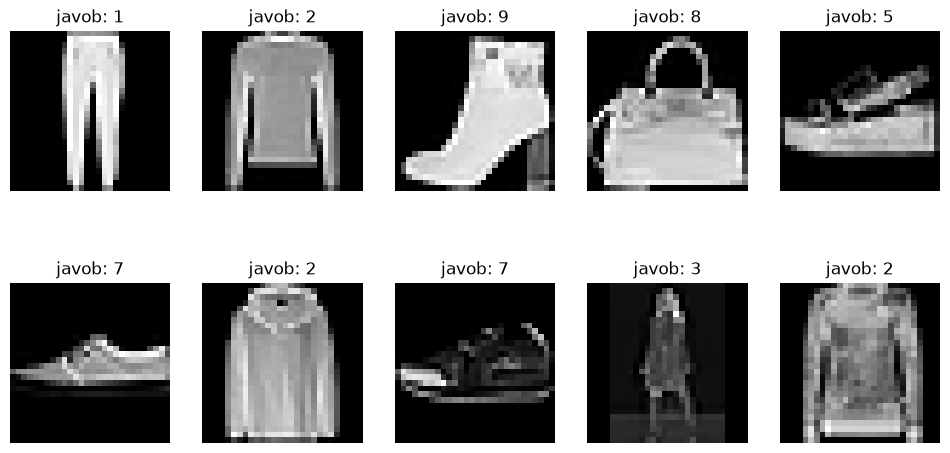

In [38]:
import matplotlib.pyplot as plt
import numpy as np


fig, ax = plt.subplots(2, 5, figsize=(12, 6))
for i in range(2):
    for j in range(5):
        idx = np.random.randint(len(train_ds))
        rasm, javob = train_ds[idx]
        ax[i, j].imshow(rasm.permute(1, 2, 0).squeeze(), cmap='gray')
        ax[i, j].set_title(f"javob: {javob}")
        ax[i, j].axis('off')
plt.show()